# 🚀 Practice Day 45

**📅 Date:** **2026-10-28**  
**📁 Category:** **Phase 1 · 데이터 클리닝 (Round 4/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Diagnose data quality issues in messy auto repair shop records (missing values, duplicates, type errors, inconsistent categories, cost outliers)
  (지저분한 자동차 정비소 서비스 기록의 품질 문제 진단: 결측치·중복행·타입 오류·표기 불일치·비용 이상값)
- Clean the dataset so it's reliable enough to analyze
  (분석 가능한 수준으로 데이터 정제하기)
- Summarize cost by service type once the data is clean
  (정제 후 서비스 유형별 비용 요약하기)

---
# 📂 Dataset

**Dataset Name:** Ironclad Auto Service — Service Records (Raw) / Ironclad Auto Service — 서비스 기록 (원본, 지저분한 버전)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 284 raw service records (single table) across 6 service types (Oil Change, Tire Rotation, Brake Repair, Engine Diagnostic, Battery Replacement, Transmission Service) and 4 vehicle types (Sedan, SUV, Truck, Van). Costs are in USD. Deliberately includes missing values, exact duplicate rows, a `cost` column mixing numbers with junk text, inconsistent capitalization/spacing in `service_type` and `vehicle_type`, and out-of-range cost outliers (negative and implausibly high values).
(284건의 자동차 정비소 서비스 원본 기록입니다(단일 테이블). 6개 서비스 유형(Oil Change/Tire Rotation/Brake Repair/Engine Diagnostic/Battery Replacement/Transmission Service), 4개 차량 유형(Sedan/SUV/Truck/Van)에 걸쳐 있습니다. 비용은 USD입니다. 결측치, 완전 중복행, 숫자와 문자가 섞인 cost 컬럼, service_type·vehicle_type의 대소문자/공백 표기 불일치, 범위를 벗어난 cost 이상값(음수·비현실적 고액)이 의도적으로 섞여 있습니다.)

## Dataset Preview

In [133]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate messy auto repair shop service records ---
n_clean = 270
n_dupe = 14

service_types = ['Oil Change', 'Tire Rotation', 'Brake Repair', 'Engine Diagnostic', 'Battery Replacement', 'Transmission Service']
service_w = [0.28, 0.18, 0.16, 0.14, 0.13, 0.11]
base_cost = {'Oil Change': 45, 'Tire Rotation': 35, 'Brake Repair': 180,
             'Engine Diagnostic': 90, 'Battery Replacement': 130, 'Transmission Service': 420}  # USD

vehicle_types = ['Sedan', 'SUV', 'Truck', 'Van']
vehicle_w = [0.42, 0.32, 0.16, 0.10]

service_choice = rng.choice(service_types, size=n_clean, p=service_w)
vehicle_choice = rng.choice(vehicle_types, size=n_clean, p=vehicle_w)
service_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 220, size=n_clean), unit='D')

cost = np.array([base_cost[s] for s in service_choice]) * rng.normal(1.0, 0.10, n_clean)
cost = cost.round(0).astype(int)  # nearest USD

df = pd.DataFrame({
    'service_id': [f'SV{str(i).zfill(4)}' for i in range(1, n_clean + 1)],
    'service_type': service_choice,
    'vehicle_type': vehicle_choice,
    'cost': cost,
    'service_date': service_dates
})
df['service_type'] = df['service_type'].astype(object)
df['vehicle_type'] = df['vehicle_type'].astype(object)
df['cost'] = df['cost'].astype(object)
df['service_date'] = df['service_date'].astype(object)

# --- inject realistic messiness (this is what you'll clean up below) ---

# 1) Inconsistent text formatting: service_type casing/whitespace
mess_idx = rng.choice(df.index, size=int(n_clean * 0.4), replace=False)
for i in mess_idx:
    base = df.loc[i, 'service_type']
    df.loc[i, 'service_type'] = rng.choice([base.lower(), base.upper(), ' ' + base, base + ' '])

# 2) Inconsistent text formatting: vehicle_type casing/whitespace
mess_idx2 = rng.choice(df.index, size=int(n_clean * 0.35), replace=False)
for i in mess_idx2:
    base = df.loc[i, 'vehicle_type']
    df.loc[i, 'vehicle_type'] = rng.choice([base.lower(), base.upper(), ' ' + base, base + ' '])

# 3) cost: non-numeric junk values + unrealistic outliers
used_idx = set()
cost_junk_vals = ['N/A', 'pending', 'TBD', 'unpaid']
junk_idx = rng.choice(df.index, size=10, replace=False)
used_idx.update(junk_idx.tolist())
for j, i in enumerate(junk_idx):
    df.loc[i, 'cost'] = cost_junk_vals[j % len(cost_junk_vals)]

avail = df.index.difference(list(used_idx))
outlier_idx = rng.choice(avail, size=8, replace=False)
used_idx.update(outlier_idx.tolist())
outlier_vals = [-50, -15, 3200, 2800, -8, 4100, -25, 3500]  # USD
for j, i in enumerate(outlier_idx):
    df.loc[i, 'cost'] = outlier_vals[j % len(outlier_vals)]

# 4) Missing values scattered across columns
cost_avail = df.index.difference(list(used_idx))
df.loc[rng.choice(cost_avail, size=9, replace=False), 'cost'] = np.nan
for col, n_missing in [('vehicle_type', 8), ('service_type', 7), ('service_date', 8)]:
    df.loc[rng.choice(df.index, size=n_missing, replace=False), col] = np.nan

# 5) Duplicate rows (simulates a shop-management system logging some invoices twice)
dupe_rows = df.sample(n=n_dupe, random_state=7)
df = pd.concat([df, dupe_rows], ignore_index=True)

# Shuffle so duplicates aren't sitting next to their source row
df = df.sample(frac=1, random_state=99).reset_index(drop=True)

df.head(10)


,service_id,service_type,vehicle_type,cost,service_date
0,SV0144,Brake Repair,Truck,157,NaN
1,SV0204,OIL CHANGE,Sedan,43,2024-06-25 00:00:00
2,SV0008,Battery Replacement,SUV,134,2024-08-05 00:00:00
3,SV0219,Transmission Service,SUV,364,2024-04-26 00:00:00
4,SV0003,Battery Replacement,Sedan,154,2024-07-29 00:00:00
5,SV0120,Engine Diagnostic,Truck,85,2024-05-16 00:00:00
6,SV0160,battery replacement,TRUCK,114,2024-01-10 00:00:00
7,SV0201,Battery Replacement,Sedan,121,2024-06-11 00:00:00
8,SV0016,Oil Change,Sedan,43,2024-01-18 00:00:00
9,SV0051,Oil Change,Van,41,2024-03-30 00:00:00


## Dataset Information

In [134]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 284 entries, 0 to 283
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   service_id    284 non-null    str   
 1   service_type  277 non-null    object
 2   vehicle_type  276 non-null    object
 3   cost          274 non-null    object
 4   service_date  276 non-null    object
dtypes: object(4), str(1)
memory usage: 11.2+ KB

Shape: (284, 5)


,service_id,service_type,vehicle_type,cost,service_date
count,284,277,276,274,276
unique,270,30,19,137,152
top,SV0003,Oil Change,Sedan,41,2024-07-06 00:00:00
freq,2,51,80,10,5


---
# ❓ Business Questions

1. **(Analysis)** How many missing values exist in each column, and how many exact duplicate rows are in the dataset?
   (각 컬럼별 결측치 개수와 완전 중복행의 개수는?)
2. **(Analysis)** How many rows have a non-numeric/invalid `cost` value, and what inconsistent formats appear in `service_type` and `vehicle_type`?
   (`cost`에서 숫자로 변환되지 않는 값은 몇 건이며, `service_type`과 `vehicle_type`에는 어떤 표기 불일치가 나타나는가?)
3. **(Analysis)** Among valid numeric costs, how many fall outside a realistic range (e.g., negative or implausibly high)?
   (유효한 숫자형 cost 중 현실적인 범위를 벗어난 값(음수 또는 비현실적 고액)은 몇 건인가?)
4. **(Visualization)** After cleaning, what is the average cost by service type?
   (정제 후, 서비스 유형별 평균 비용은?)
5. **(Visualization)** After cleaning, what does the overall cost distribution look like?
   (정제 후, 전체 비용 분포는 어떤 모습인가?)

---
# 🔍 Data Cleaning Check


In [135]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
service_id       0
service_type     7
vehicle_type     8
cost            10
service_date     8
dtype: int64

Duplicate rows: 14

Dtypes
service_id         str
service_type    object
vehicle_type    object
cost            object
service_date    object
dtype: object

Column names
['service_id', 'service_type', 'vehicle_type', 'cost', 'service_date']

Text columns — unique counts
service_id      270
service_type     30
vehicle_type     19
cost            137
service_date    152
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** How many missing values exist in each column, and how many exact duplicate rows are in the dataset? (각 컬럼별 결측치 개수와 완전 중복행의 개수는?)

**Result:** `service_type` has **7** missing values, `vehicle_type` **8**, `cost` **10**, and `service_date` **8**. Exact duplicate rows: **14**.  
(`service_type` 결측 7, `vehicle_type` 8, `cost` 10, `service_date` 8. 완전 중복행 14)

**Insight:** Those missing cells add to **33**. `service_id` has **0**. After the **14** duplicates are removed, missing `cost` falls from **10** to **9**.  
(결측 칸을 더하면 33. `service_id`는 0. 중복 14건을 빼면 `cost` 결측은 10에서 9로 줄어듦)

In [136]:
# Question 1: missing values per column + exact duplicate row count

print(df.isnull().sum())
print("\ncount of exact duplicate rows:", df.duplicated().sum())

cleaned_df = df.copy()

cleaned_df.drop_duplicates(inplace=True)

service_id       0
service_type     7
vehicle_type     8
cost            10
service_date     8
dtype: int64

count of exact duplicate rows: 14


## Question 2

**Question:** How many rows have a non-numeric/invalid `cost` value, and what inconsistent formats appear in `service_type` and `vehicle_type`? (`cost` 무효값 건수와 표기 불일치는?)

**Result:** After `to_numeric`, missing `cost` rises from **9** to **19**, so **10** text values (`N/A`, `pending`, `TBD`, `unpaid`) are invalid. `service_type` and `vehicle_type` mix lowercase, uppercase, and leading or trailing spaces. **7** service types and **8** vehicle types stay missing.  
(`to_numeric` 뒤 `cost` 결측이 9에서 19로 늘어, 문자 값 10건이 무효. `service_type`과 `vehicle_type`은 소문자·대문자·앞뒤 공백이 섞여 있음. 서비스 유형 7건, 차종 8건은 그대로 비어 있음)

**Insight:** `strip` and `title` collapse each column to its real names: six service types, and Truck, Sedan, SUV, Van. A blank type stays blank.  
(`strip`과 `title` 뒤에는 서비스 유형 6개와 Truck, Sedan, SUV, Van만 남음. 빈 유형은 빈 채로 둠)

In [137]:
df['service_type'].unique()

array(['Brake Repair', np.str_('OIL CHANGE'), 'Battery Replacement',
       'Transmission Service', 'Engine Diagnostic',
       np.str_('battery replacement'), np.str_('Oil Change '),
       'Oil Change', np.str_('oil change'), np.str_('Tire Rotation '),
       nan, 'Tire Rotation', np.str_(' Battery Replacement'),
       np.str_('ENGINE DIAGNOSTIC'), np.str_(' Oil Change'),
       np.str_('Engine Diagnostic '), np.str_('tire rotation'),
       np.str_('TIRE ROTATION'), np.str_('BATTERY REPLACEMENT'),
       np.str_(' Brake Repair'), np.str_(' Tire Rotation'),
       np.str_(' Engine Diagnostic'), np.str_('engine diagnostic'),
       np.str_('Brake Repair '), np.str_('TRANSMISSION SERVICE'),
       np.str_('transmission service'), np.str_(' Transmission Service'),
       np.str_('brake repair'), np.str_('Battery Replacement '),
       np.str_('BRAKE REPAIR'), np.str_('Transmission Service ')],
      dtype=object)

In [138]:
# Question 2: invalid cost values + service_type/vehicle_type formatting inconsistencies
cleaned_df['service_type'] = cleaned_df['service_type'].str.strip()
cleaned_df['service_type'] = cleaned_df['service_type'].str.title()

cleaned_df['service_type'].unique()

array(['Brake Repair', 'Oil Change', 'Battery Replacement',
       'Transmission Service', 'Engine Diagnostic', 'Tire Rotation', nan],
      dtype=object)

In [139]:
cleaned_df.loc[cleaned_df['service_type'].isnull()]

,service_id,service_type,vehicle_type,cost,service_date
14,SV0122,NaN,Sedan,105,2024-04-15 00:00:00
61,SV0073,NaN,Truck,129,2024-04-04 00:00:00
65,SV0104,NaN,sedan,NaN,2024-04-08 00:00:00
134,SV0206,NaN,Sedan,45,2024-01-11 00:00:00
186,SV0088,NaN,truck,183,2024-03-28 00:00:00
202,SV0262,NaN,SUV,116,2024-01-31 00:00:00
266,SV0193,NaN,Van,54,2024-07-23 00:00:00


In [140]:
df['vehicle_type'].unique()

array(['Truck', 'Sedan', 'SUV', np.str_('TRUCK'), 'Van', np.str_('suv'),
       np.str_('van'), nan, np.str_(' SUV'), np.str_('VAN'),
       np.str_('SEDAN'), np.str_(' Sedan'), np.str_('Sedan '),
       np.str_('Van '), np.str_('truck'), np.str_('sedan'),
       np.str_(' Van'), np.str_('SUV '), np.str_('Truck '),
       np.str_(' Truck')], dtype=object)

In [141]:
cleaned_df['vehicle_type'] = cleaned_df['vehicle_type'].str.strip()
cleaned_df['vehicle_type'] = cleaned_df['vehicle_type'].str.title()
cleaned_df['vehicle_type'] = cleaned_df['vehicle_type'].replace({'Suv': 'SUV'})
cleaned_df['vehicle_type'].unique()

array(['Truck', 'Sedan', 'SUV', 'Van', nan], dtype=object)

In [142]:
cleaned_df.loc[cleaned_df['vehicle_type'].isnull()]

,service_id,service_type,vehicle_type,cost,service_date
16,SV0119,Tire Rotation,NaN,35,2024-06-25 00:00:00
81,SV0157,Tire Rotation,NaN,40,2024-01-02 00:00:00
112,SV0154,Brake Repair,NaN,2800,2024-06-13 00:00:00
113,SV0009,Oil Change,NaN,41,2024-05-23 00:00:00
197,SV0228,Brake Repair,NaN,145,2024-02-22 00:00:00
203,SV0110,Transmission Service,NaN,456,2024-01-02 00:00:00
231,SV0096,Engine Diagnostic,NaN,73,2024-03-15 00:00:00
244,SV0179,Transmission Service,NaN,421,2024-04-28 00:00:00


In [143]:
df['cost'].unique()

array([157, 43, 134, 364, 154, 85, 114, 121, 41, 40, -15, 'pending', 105,
       47, 35, 39, 142, 136, 111, 195, 443, 32, 88, 33, 93, 192, 44, 139,
       87, 185, 115, 82, 38, 34, 45, 179, 212, 104, 100, 'TBD', 420, 31,
       143, 176, 37, 178, 138, 129, nan, 81, 160, 90, 171, 'N/A', 36, 89,
       'unpaid', 378, 74, 159, 135, 69, 108, 497, 46, 49, 80, 97, 389,
       182, 53, 471, 2800, 109, 184, 189, 180, 110, 162, 170, 177, 130,
       421, 103, 50, 423, 59, -25, 174, 131, 51, 122, 203, 480, 56, 365,
       431, 70, 187, 183, 404, 42, 413, 101, 145, 94, 116, 456, 117, 29,
       204, 422, 132, 197, 373, 48, 75, 429, 3500, 124, 191, 73, 406, 30,
       308, 374, 3200, 430, 26, -8, -50, 140, 161, 54, 4100, 173, 28, 461],
      dtype=object)

In [144]:
cleaned_df['cost'].isnull().sum()

np.int64(9)

In [145]:
cleaned_df['cost'] = pd.to_numeric(cleaned_df['cost'], errors='coerce')

cleaned_df['cost'].unique()

array([ 157.,   43.,  134.,  364.,  154.,   85.,  114.,  121.,   41.,
         40.,  -15.,   nan,  105.,   47.,   35.,   39.,  142.,  136.,
        111.,  195.,  443.,   32.,   88.,   33.,   93.,  192.,   44.,
        139.,   87.,  185.,  115.,   82.,   38.,   34.,   45.,  179.,
        212.,  104.,  100.,  420.,   31.,  143.,  176.,   37.,  178.,
        138.,  129.,   81.,  160.,   90.,  171.,   36.,   89.,  378.,
         74.,  159.,  135.,   69.,  108.,  497.,   46.,   49.,   80.,
         97.,  389.,  182.,   53.,  471., 2800.,  109.,  184.,  189.,
        180.,  110.,  162.,  170.,  177.,  130.,  421.,  103.,   50.,
        423.,   59.,  -25.,  174.,  131.,   51.,  122.,  203.,  480.,
         56.,  365.,  431.,   70.,  187.,  183.,  404.,   42.,  413.,
        101.,  145.,   94.,  116.,  456.,  117.,   29.,  204.,  422.,
        132.,  197.,  373.,   48.,   75.,  429., 3500.,  124.,  191.,
         73.,  406.,   30.,  308.,  374., 3200.,  430.,   26.,   -8.,
        -50.,  140.,

In [146]:
cleaned_df['cost'].isnull().sum()


np.int64(19)

## Question 3

**Question:** Among valid numeric costs, how many fall outside a realistic range? (유효한 숫자형 cost 중 현실적 범위를 벗어난 값은?)

**Result:** **8** numeric costs are outside the range. The high values are **$4,100**, **$3,500**, **$3,200**, and **$2,800**. The negative values are **-$8**, **-$15**, **-$25**, and **-$50**.  
(범위를 벗어난 숫자 비용은 8건. 고액은 $4,100, $3,500, $3,200, $2,800. 음수는 -$8, -$15, -$25, -$50)

**Insight:** Among **251** numeric costs, the mean is **$168.32** and the median is **$81**. The mean is **$87.32** above the median because of those four high costs.  
(숫자 비용 251건의 평균은 $168.32, 중앙값은 $81. 평균이 중앙값보다 $87.32 높은 것은 고액 4건 때문)

In [147]:
# Question 3: unrealistic cost values among valid numeric costs
cleaned_df['cost'].describe()

count     251.000000
mean      168.318725
std       431.572087
min       -50.000000
25%        41.000000
50%        81.000000
75%       155.500000
max      4100.000000
Name: cost, dtype: float64

In [148]:
cleaned_df.loc[(cleaned_df['cost'] < 0) | (cleaned_df['cost'] > 1000)].sort_values('cost', ascending=False)

,service_id,service_type,vehicle_type,cost,service_date
268,SV0216,Engine Diagnostic,Sedan,4100.0,2024-04-23 00:00:00
228,SV0124,Tire Rotation,SUV,3500.0,2024-06-16 00:00:00
246,SV0023,Transmission Service,Van,3200.0,2024-07-21 00:00:00
112,SV0154,Brake Repair,NaN,2800.0,2024-06-13 00:00:00
256,SV0250,Tire Rotation,Truck,-8.0,2024-03-16 00:00:00
11,SV0085,Oil Change,SUV,-15.0,NaN
152,SV0246,Battery Replacement,Sedan,-25.0,2024-02-11 00:00:00
261,SV0251,Engine Diagnostic,Truck,-50.0,2024-04-08 00:00:00


---
# 📈 Visualization

**Chart 1:** Bar chart — average cost by service type (막대그래프: 서비스 유형별 평균 비용)

*Interpretation:* After dropping costs at or below **$0** or at or above **$1,000**, the averages are Transmission Service **$416.32**, Brake Repair **$179.94**, Battery Replacement **$125.81**, Engine Diagnostic **$88.21**, Oil Change **$45.28**, and Tire Rotation **$34.70**.  
($0 이하와 $1,000 이상을 뺀 평균은 Transmission Service $416.32, Brake Repair $179.94, Battery Replacement $125.81, Engine Diagnostic $88.21, Oil Change $45.28, Tire Rotation $34.70)

---

**Chart 2:** Histogram — distribution of cost (히스토그램: 비용 분포)

*Interpretation:* Most of the remaining costs sit under **$200**. A smaller cluster sits near **$400**, in line with the Transmission Service average of **$416.32**.  
(남은 비용은 대부분 $200 미만. $400 근처에 작은 묶음이 있고, 이는 Transmission Service 평균 $416.32와 맞음)

service_type
Transmission Service    416.320000
Brake Repair            179.941176
Battery Replacement     125.812500
Engine Diagnostic        88.212121
Oil Change               45.275362
Tire Rotation            34.704545
Name: cost, dtype: float64


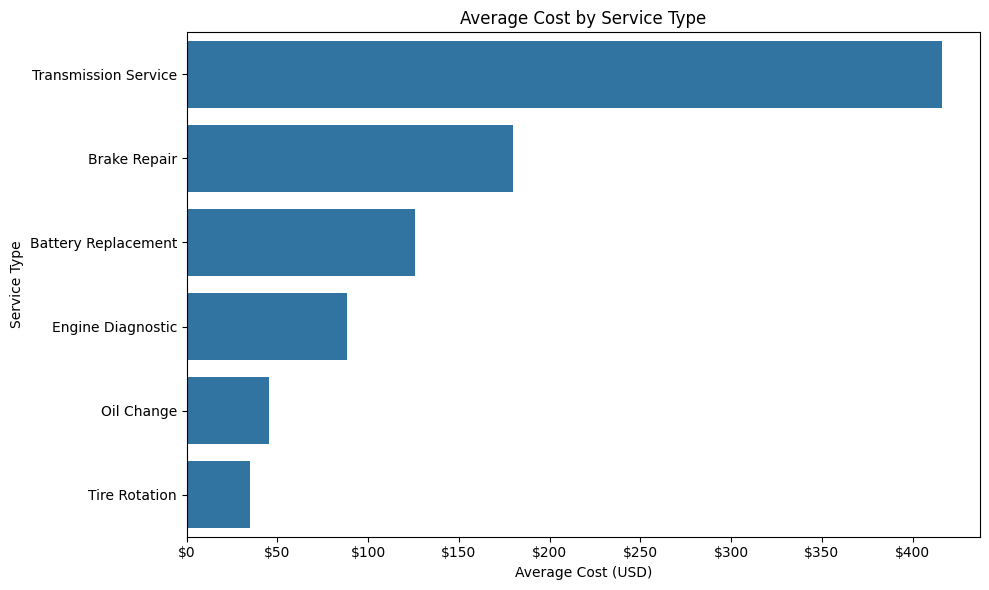

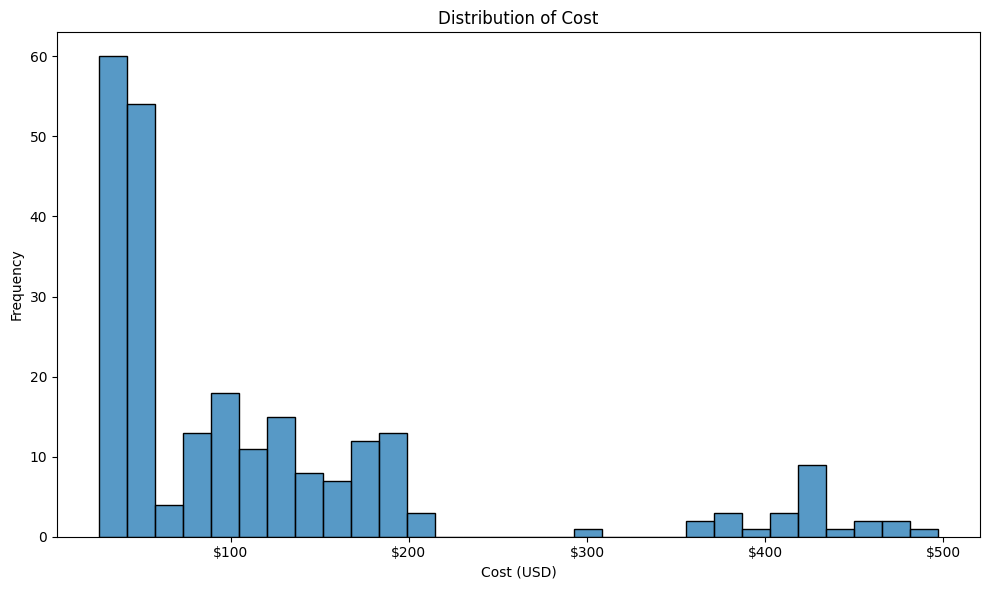

In [149]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: average cost by service_type (bar chart)
chart_data = cleaned_df.loc[(cleaned_df['cost'] > 0) & (cleaned_df['cost'] < 1000)]


data = chart_data.groupby('service_type')['cost'].mean().sort_values(ascending=False)
print(data)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=data.values, y=data.index, ax=ax, errorbar=None)
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Average Cost by Service Type')
ax.set_xlabel('Average Cost (USD)')
ax.set_ylabel('Service Type')
plt.tight_layout()
plt.show()

# Chart 2: distribution of cost (histogram)
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(chart_data['cost'], bins=30, ax=ax)
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Distribution of Cost')
ax.set_xlabel('Cost (USD)')
ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- The raw table has **14** exact duplicate rows and **33** missing cells.  
  (원본에는 완전 중복행 14건과 결측 칸 33개가 있음)
- **10** cost values are text, and **8** numeric costs are outside a realistic range.  
  (비용 10건은 문자이고, 숫자 비용 8건은 현실적인 범위 밖)
- With those costs removed, Transmission Service averages **$416.32** and Tire Rotation averages **$34.70**.  
  (그 비용을 빼면 Transmission Service 평균은 $416.32, Tire Rotation 평균은 $34.70)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Drop the **8** out-of-range costs before quoting an average. The mean of all **251** numeric costs is **$168.32**, while the median is **$81**.  
   (평균을 말하기 전에 범위 밖 8건을 뺄 것. 숫자 비용 251건의 평균은 $168.32, 중앙값은 $81)
2. Leave the **7** blank service types and **8** blank vehicle types empty. `strip` and `title` only fix text that is already there.  
   (비어 있는 서비스 유형 7건과 차종 8건은 비워 둘 것. `strip`과 `title`은 이미 있는 글자만 고침)
3. Compare service types with the cleaned averages. Transmission Service is **$236.38** above Brake Repair.  
   (서비스 유형은 정제한 평균으로 비교. Transmission Service가 Brake Repair보다 $236.38 높음)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- `str.title()` turned SUV into Suv.  
  (`str.title()`이 SUV를 Suv로 바꿨음)
- Chart 1 put the service names on the axis labeled Average Cost, and the dollar values on the axis labeled Service Type.  
  (차트 1에서 서비스 이름이 Average Cost 축에, 금액이 Service Type 축에 있었음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `drop_duplicates` removes the **14** copied rows. Missing `cost` then goes from **10** to **9**.  
  (`drop_duplicates`가 복사된 14건을 뺌. 그다음 `cost` 결측은 10에서 9)
- `to_numeric(..., errors='coerce')` turns the **10** text costs into missing values, so the null count becomes **19**.  
  (`to_numeric(..., errors='coerce')`가 문자 비용 10건을 결측으로 바꿔 결측이 19가 됨)
- Costs below **$0** or at **$1,000** and above are the **8** outliers. `str.title()` needs `replace({'Suv': 'SUV'})`, and a cost axis needs USD.  
  ($0 미만이거나 $1,000 이상인 비용이 이상치 8건. `str.title()` 뒤에는 `replace({'Suv': 'SUV'})`가 필요하고, 비용 축에는 USD가 필요함)  

---
# 🧠 Reflection

**What was difficult?**  
Separating text costs from missing costs, and keeping SUV as SUV.  
(문자 비용과 원래 결측 비용을 나누는 것, 그리고 SUV를 SUV로 남기는 것)

**Why?**  
`to_numeric` adds the **10** text values to the **9** missing costs. `title()` rewrites SUV.  
(`to_numeric`은 문자 10건을 결측 9건에 더함. `title()`은 SUV를 다시 씀)

**How did I solve it?**  
Counted nulls before and after `to_numeric`, replaced Suv with SUV, and filtered the chart to costs above **$0** and below **$1,000**.  
(`to_numeric` 전후 결측을 세고, Suv를 SUV로 바꾸고, 차트는 $0 초과 $1,000 미만만 씀)

**What would I do differently next time?**  
Check the axis title against the labels on that axis, and check SUV after `title()`.  
(축 제목이 그 축의 라벨과 같은지 보고, `title()` 뒤에 SUV를 확인하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
The **14** duplicates, the **10** text costs, and the **8** outliers are clear. SUV and the cost-axis title still need a check.  
(중복 14건, 문자 비용 10건, 이상치 8건은 이해함. SUV와 비용 축 제목은 아직 확인이 필요함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
Finding the mess was familiar. The hard part was the null count jumping from **9** to **19**.  
(지저분한 부분을 찾는 것은 익숙함. 어려운 부분은 결측이 9에서 19로 늘어난 것이었음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 46 — visualization basics (Round 4/5)  
  (막대·선·파이로 영화 장르와 월별 관객 보기)  